In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

base = "/content/drive/MyDrive/Phishing_Detection_Project"
for folder in ["data/raw", "data/processed", "notebooks", "src", "models", "app", "reports", "tests"]:
    os.makedirs(f"{base}/{folder}", exist_ok=True)

os.chdir(base)
print("Working directory:", os.getcwd())

In [ ]:
!pip install ucimlrepo shap tldextract joblib

In [ ]:
!pip freeze > requirements.txt

In [ ]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

data = fetch_ucirepo(id=327)
df = pd.concat([data.data.features, data.data.targets], axis=1)
df.to_csv(f"{base}/data/raw/uci_phishing.csv", index=False)


In [ ]:
print("Shape:", df.shape)
df.head()

In [ ]:
print("Columns:", df.columns.tolist())

In [ ]:
print("Missing values:", df.isnull().sum().sum())

print("Duplicate rows:", df.duplicated().sum())

target = df.columns[-1]
print(df[target].value_counts())
print(df[target].value_counts(normalize=True))

In [ ]:
# changing the values as phishing = 1, legitimate = 0
df["label"] = (df["result"] == -1).astype(int)
df = df.drop(columns=["result"])
print(df["label"].value_counts())

In [ ]:
#grouping rows that have identical features but different labels
feature_cols = [c for c in df.columns if c != "label"]
conflicts = df.groupby(feature_cols)["label"].nunique()
print("Feature patterns with conflicting labels:", (conflicts > 1).sum())

# removing duplicates
df_clean = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df_clean.shape)
print(df_clean["label"].value_counts(normalize=True))

df_clean.to_csv(f"{base}/data/processed/uci_clean.csv", index=False)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 11))
sns.heatmap(df_clean.corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Feature Correlation Heatmap")
plt.show()

# Which features correlate most with phishing?
print(df_clean.corr()["label"].drop("label").sort_values(key=abs, ascending=False).head(10))

In [ ]:
print(pd.crosstab(df_clean["domain_registration_length"], df_clean["label"], normalize="index"))

In [ ]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns="label")
y = df_clean["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

models = {
    "Logistic Regression": Pipeline([("scaler", StandardScaler()),
                                     ("clf", LogisticRegression(max_iter=1000))]),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "SVM": Pipeline([("scaler", StandardScaler()),
                     ("clf", SVC(probability=True, random_state=42))]),
    "XGBoost": XGBClassifier(eval_metric="logloss", random_state=42),
}

In [ ]:
import time
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []

for name, model in models.items():
    t0 = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - t0

    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]

    cv_res = cross_validate(model, X_train, y_train, cv=cv, scoring=["f1", "recall"])

    rows.append({
        "Model": name,
        "Train Acc": model.score(X_train, y_train),
        "Test Acc": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "CV F1 (mean)": cv_res["test_f1"].mean(),
        "CV F1 (std)": cv_res["test_f1"].std(),
        "Train time (s)": train_time,
    })

results = pd.DataFrame(rows).round(4).set_index("Model")
results

In [ ]:
results.to_csv(f"{base}/reports/baseline_results.csv")

from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, ax=ax, display_labels=["Legit", "Phish"], colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# XGBoost
xgb_params = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.7, 0.85, 1.0],
}
xgb_search = RandomizedSearchCV(
    XGBClassifier(eval_metric="logloss", random_state=42),
    xgb_params, n_iter=25, scoring="f1", cv=cv, random_state=42, n_jobs=-1)
xgb_search.fit(X_train, y_train)
print("Best XGB params:", xgb_search.best_params_)
print("Best CV F1:", round(xgb_search.best_score_, 4))

# Random Forest
rf_params = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 10, 15, 20],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"],
}
rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42),
    rf_params, n_iter=20, scoring="f1", cv=cv, random_state=42, n_jobs=-1)
rf_search.fit(X_train, y_train)
print("Best RF params:", rf_search.best_params_)
print("Best CV F1:", round(rf_search.best_score_, 4))

Best XGB params: {'subsample': 1.0, 'n_estimators': 100, 'max_depth': 5, 'learning_rate': 0.2, 'colsample_bytree': 1.0}
Best CV F1: 0.9548


In [ ]:
best_xgb = xgb_search.best_estimator_
best_rf = rf_search.best_estimator_

for name, m in [("Tuned XGBoost", best_xgb), ("Tuned Random Forest", best_rf)]:
    pred = m.predict(X_test)
    proba = m.predict_proba(X_test)[:, 1]
    print(name,
          "| Acc:", round(accuracy_score(y_test, pred), 4),
          "| Recall:", round(recall_score(y_test, pred), 4),
          "| F1:", round(f1_score(y_test, pred), 4),
          "| AUC:", round(roc_auc_score(y_test, proba), 4))

In [ ]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(7, 6))
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_title("ROC Curves")
ax.legend()
plt.savefig(f"{base}/reports/roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
import shap

imp = pd.Series(best_xgb.feature_importances_, index=X.columns).sort_values(ascending=False)
imp.head(10).plot(kind="barh", figsize=(7, 5)).invert_yaxis()
plt.title("Top 10 Feature Importances (XGBoost)")
plt.show()


explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer.shap_values(X_test)
shap.summary_plot(shap_values, X_test, show=False)
plt.savefig(f"{base}/reports/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
print(pd.crosstab(df_clean["sslfinal_state"], df_clean["label"], normalize="index"))

label                  0         1
sslfinal_state                    
-1              0.124060  0.875940
 0              0.009709  0.990291
 1              0.853000  0.147000


In [ ]:
import joblib

# Save the benchmark model and the results
joblib.dump(best_xgb, f"{base}/models/uci_xgb_benchmark.pkl")

final = pd.DataFrame({
    "Tuned XGBoost": [accuracy_score(y_test, best_xgb.predict(X_test)),
                      recall_score(y_test, best_xgb.predict(X_test)),
                      f1_score(y_test, best_xgb.predict(X_test)),
                      roc_auc_score(y_test, best_xgb.predict_proba(X_test)[:, 1])],
    "Tuned Random Forest": [accuracy_score(y_test, best_rf.predict(X_test)),
                            recall_score(y_test, best_rf.predict(X_test)),
                            f1_score(y_test, best_rf.predict(X_test)),
                            roc_auc_score(y_test, best_rf.predict_proba(X_test)[:, 1])],
}, index=["Accuracy", "Recall", "F1", "ROC-AUC"]).round(4)
final.to_csv(f"{base}/reports/tuned_results.csv")
print(final)

          Tuned XGBoost  Tuned Random Forest
Accuracy         0.9556               0.9427
Recall           0.9487               0.9255
F1               0.9566               0.9435
ROC-AUC          0.9930               0.9902


In [ ]:
tranco = pd.read_csv(f"{base}/data/raw/tranco.csv", header=None, names=["rank", "domain"])
print("Tranco:", tranco.shape)
print(tranco.head())

from ucimlrepo import fetch_ucirepo

phiusiil = fetch_ucirepo(id=967)
df_url = pd.concat([phiusiil.data.features, phiusiil.data.targets], axis=1)
df_url.to_csv(f"{base}/data/raw/phiusiil.csv", index=False)

print(df_url.shape)
print(df_url.columns.tolist())
print(df_url.iloc[:, :3].head())

Tranco: (1001, 2)
                                                         rank       domain
rank domain         date       year month month_name  list_id  data_source
1    google.com     2026-08-22 2026 8     August        74V8X       Tranco
2    cloudflare.com 2026-08-22 2026 8     August        74V8X       Tranco
3    gstatic.com    2026-08-22 2026 8     August        74V8X       Tranco
4    facebook.com   2026-08-22 2026 8     August        74V8X       Tranco
(235795, 55)
['URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchSco

In [ ]:
print(df_url["label"].value_counts())

for lab in [0, 1]:
    print(f"\nlabel = {lab}")
    for u in df_url[df_url["label"] == lab]["URL"].sample(8, random_state=1):
        print("  ", u)

label
1    134850
0    100945
Name: count, dtype: int64

label = 0
   https://tracking.selfserviceib.com/tracking/1/click/ejorccw7cfkwhilpbcpgu7mn1hs1pqyi7ko2fgolwhjz20ggw-kcr8a72__zd3akduk-lwxcvp0nxybfpwan3e5aa6kl8oka0lu4jbl-eqbzd8rhbueigtfhn-_tr4o5ruxmkukw2lpciukyb8tmlpuy82to0mhbi4nvvgycrqsh_6ah-5b7zcke4-gmdzhllp8mhbogmxy1zsmnxzapvzzona4txmcjhcy8wgjul7vyp3a_7br_-n7saoen0zuabg19babghhzotbbs8lyau6vjzrlmtgvq5gvl0mf4mvqzqrjt7dnqowq325u7xq-yrni_py7e-jeltjmwh3ggi7oiiqfqavqmqyod55dwk6ctni0g9jvrtq_-uxqfuby_-ww22kni20qibyi8umza5x-6ejwpetbdo8qzvokooez2wvn2qvknqxe0tkc8-vh32c6a8epif2boookcm3vy531pl3ybajw4hb8ptdqzvrn5msoglsqbfgrq_juupjivt7opnhuid1l5tn0y5qymkejl5r9xpeamisa4cw1k0tgyug9-cfaatrekgjierw8mro_ptcfwffs_u3az1xykptx6sdvvyrt7yjfrbv50xw1-rf5e9bphdwlhgjvjoqcep1aj8cmbbutzfd_k5nribufd41uofrto7dcauzdix5swalpohd0wxekhpcnsucyv_qhlejjb9n7kele-8r_m3a==
   https://maria.susypro.com/
   https://exchangeportal-owa-auth-login-aspx-hyttgygh.infura-ipfs.io/ipfs/qmv5almanqswnizvrextgpbq5ic92pvafagzs1ivqmax

In [ ]:
df_url["is_phish"] = (df_url["label"] == 0).astype(int)   # 1 = phishing

In [ ]:
print("Duplicate URLs:", df_url["URL"].duplicated().sum())
print("Duplicate URLs with conflicting labels:",
      (df_url.groupby("URL")["is_phish"].nunique() > 1).sum())

Duplicate URLs: 425
Duplicate URLs with conflicting labels: 0


In [ ]:
from urllib.parse import urlparse

def safe_parse(u):
    try:
        return urlparse(u)
    except ValueError:
        return None

d = df_url[["URL", "is_phish"]].copy()
parsed = d["URL"].apply(safe_parse)

d["has_path"]    = parsed.apply(lambda p: int(p is not None and len(p.path.strip("/")) > 0))
d["has_query"]   = parsed.apply(lambda p: int(p is not None and len(p.query) > 0))
d["https"]       = parsed.apply(lambda p: int(p is not None and p.scheme == "https"))
d["starts_www"]  = d["URL"].str.contains("://www.").astype(int)
d["url_len"]     = d["URL"].str.len()

print(d.groupby("is_phish")[["has_path", "has_query", "https", "starts_www", "url_len"]].mean().round(3))

          has_path  has_query  https  starts_www  url_len
is_phish                                                 
0            0.000       0.00  1.000       1.000   27.229
1            0.272       0.06  0.487       0.417   46.239


In [ ]:
tranco = pd.read_csv(f"{base}/data/raw/tranco.csv")
print(tranco.shape)
print(tranco.columns.tolist())
print(tranco.head(3))

(1000, 8)
['rank', 'domain', 'date', 'year', 'month', 'month_name', 'list_id', 'data_source']
   rank          domain        date  year  month month_name list_id  \
0     1      google.com  2026-08-22  2026      8     August   74V8X   
1     2  cloudflare.com  2026-08-22  2026      8     August   74V8X   
2     3     gstatic.com  2026-08-22  2026      8     August   74V8X   

  data_source  
0      Tranco  
1      Tranco  
2      Tranco  


In [ ]:
d = df_url[["URL", "label"]].copy()
d["is_phish"] = (d["label"] == 0).astype(int)
d = d.drop(columns="label").drop_duplicates(subset="URL").reset_index(drop=True)
print(d.shape, d["is_phish"].mean().round(3))

print("URLs containing '](':", d["URL"].str.contains(r"\]\(", regex=True).sum())

(235370, 2) 0.427
URLs containing '](': 0


In [ ]:
from urllib.parse import urlparse
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score, precision_score

def struct(u):
    try:
        p = urlparse(u)
        return pd.Series({
            "has_path":   int(len(p.path.strip("/")) > 0),
            "has_query":  int(len(p.query) > 0),
            "https":      int(p.scheme == "https"),
            "starts_www": int(u.startswith(("http://www.", "https://www."))),
        })
    except ValueError:
        return pd.Series({"has_path": 0, "has_query": 0, "https": 0, "starts_www": 0})

S = d["URL"].apply(struct)

looks_legit = (S.has_path == 0) & (S.has_query == 0) & (S.https == 1) & (S.starts_www == 1)
print("Phishing URLs that look structurally 'legit':",
      round(looks_legit[d.is_phish == 1].mean(), 3))
print("Legit URLs that look structurally 'legit':",
      round(looks_legit[d.is_phish == 0].mean(), 3))

Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(S, d["is_phish"], test_size=0.2,
                                              stratify=d["is_phish"], random_state=42)
tiny = DecisionTreeClassifier(max_depth=3, random_state=42).fit(Xs_tr, ys_tr)
p = tiny.predict(Xs_te)
print("Accuracy:", round(accuracy_score(ys_te, p), 4),
      "| Precision:", round(precision_score(ys_te, p), 4),
      "| Recall:", round(recall_score(ys_te, p), 4))

Phishing URLs that look structurally 'legit': 0.01
Legit URLs that look structurally 'legit': 1.0
Accuracy: 0.9956 | Precision: 1.0 | Recall: 0.9898


In [ ]:
import tldextract

ext = tldextract.TLDExtract(suffix_list_urls=())

def parts(u):
    try:
        e = ext(u)
        sub = e.subdomain
        if sub == "www":
            sub = ""
        elif sub.startswith("www."):
            sub = sub[4:]
        return pd.Series({"reg_domain": e.registered_domain, "extra_sub": int(sub != "")})
    except Exception:
        return pd.Series({"reg_domain": "", "extra_sub": 0})

d[["reg_domain", "extra_sub"]] = d["URL"].apply(parts)

print("Share with a subdomain beyond www:")
print(d.groupby("is_phish")["extra_sub"].mean().round(3))

print("\nUnique registered domains per class:")
print(d.groupby("is_phish")["reg_domain"].nunique())

top = d[d.is_phish == 1]["reg_domain"].value_counts()
print("\nTop phishing registered domains:")
print(top.head(15))
print("Share of phishing URLs on the top 20 domains:",
      round(top.head(20).sum() / top.sum(), 3))

both = set(d[d.is_phish == 1]["reg_domain"]) & set(d[d.is_phish == 0]["reg_domain"])
print("\nRegistered domains appearing in BOTH classes:", len(both))

/tmp/ipykernel_1819/514518200.py:14: DeprecationWarning: The 'registered_domain' property is deprecated and will be removed in the next major version. Use 'top_domain_under_public_suffix' instead, which has the same behavior but a more accurate name.
  return pd.Series({"reg_domain": e.registered_domain, "extra_sub": int(sub != "")})


Share with a subdomain beyond www:
is_phish
0    0.029
1    0.543
Name: extra_sub, dtype: float64

Unique registered domains per class:
is_phish
0    132117
1     43356
Name: reg_domain, dtype: int64

Top phishing registered domains:
reg_domain
web.app             5718
firebaseapp.com     5546
repl.co             3746
weeblysite.com      3079
ipfs.io             1552
workers.dev         1423
square.site         1187
dweb.link            959
xsph.ru              928
pantheonsite.io      891
google.com           782
godaddysites.com     770
duckdns.org          641
                     606
webwave.dev          559
Name: count, dtype: int64
Share of phishing URLs on the top 20 domains: 0.307

Registered domains appearing in BOTH classes: 120


In [ ]:
%%writefile /content/drive/MyDrive/Phishing_Detection_Project/src/features.py
import math
import re
from collections import Counter
from urllib.parse import urlparse
import tldextract

_ext = tldextract.TLDExtract(suffix_list_urls=())

KEYWORDS = ["login", "signin", "verify", "secure", "account", "update", "bank",
            "pay", "wallet", "auth", "support", "confirm", "billing", "recover", "unlock"]
BRANDS = ["paypal", "apple", "microsoft", "google", "amazon", "facebook", "netflix",
          "metamask", "instagram", "whatsapp", "coinbase", "binance", "outlook",
          "linkedin", "dropbox", "adobe", "chase", "wellsfargo"]

ABUSED_TLDS = {"xyz", "top", "tk", "ml", "ga", "cf", "gq", "icu", "buzz", "click", "live"}
SHORTENERS = {"bit.ly", "tinyurl.com", "t.co", "goo.gl", "ow.ly", "is.gd", "buff.ly", "cutt.ly", "rb.gy"}
CONSONANTS = set("bcdfghjklmnpqrstvwxyz")
DIGITS = set("0123456789")


def entropy(s):
    if not s:
        return 0.0
    n = len(s)
    return -sum(c / n * math.log2(c / n) for c in Counter(s).values())


def longest_run(s, chars):
    best = cur = 0
    for ch in s:
        cur = cur + 1 if ch in chars else 0
        best = max(best, cur)
    return best


def get_site(url):

    url = str(url).strip()
    if "://" not in url:
        url = "http://" + url
    try:
        host = (urlparse(url).hostname or "").lower().rstrip(".")
    except ValueError:
        host = ""
    if re.fullmatch(r"\d{1,3}(\.\d{1,3}){3}", host):
        return host, host, "", True
    e = _ext(host)
    site = f"{e.domain}.{e.suffix}" if e.domain and e.suffix else host
    return site, e.domain, e.suffix, False


def extract_features(url):
    site, label, suffix, is_ip = get_site(url)
    tld = suffix.split(".")[-1] if suffix else ""
    letters = sum(c.isalpha() for c in label)
    digits = sum(c.isdigit() for c in label)
    vowels = sum(c in "aeiou" for c in label)
    return {
        "is_ip": int(is_ip),                                   # real sites rarely use raw IPs
        "label_len": len(label),                               # long names hide intent
        "site_len": len(site),
        "num_digits": digits,                                  # auto-generated names
        "digit_ratio": digits / max(len(label), 1),
        "num_hyphens": label.count("-"),                       # brand-imitation pattern
        "hyphen_parts": len(label.split("-")) if label else 0,
        "entropy": entropy(label),                             # randomness
        "vowel_ratio": vowels / max(letters, 1),               # unpronounceable names
        "max_consonant_run": longest_run(label, CONSONANTS),
        "max_digit_run": longest_run(label, DIGITS),
        "has_punycode": int("xn--" in site),                   # lookalike characters
        "num_keywords": sum(k in label for k in KEYWORDS),     # urgency/trust words
        "brand_misuse": int(any(b in label and label != b for b in BRANDS)),
        "suffix_len": len(suffix),
        "suffix_parts": suffix.count(".") + 1 if suffix else 0,
        "abused_tld": int(tld in ABUSED_TLDS),
        "is_com": int(suffix == "com"),
        "is_gov_edu": int(tld in {"gov", "edu", "mil"}),
        "is_shortener": int(site in SHORTENERS),               # hides the destination
    }

Writing /content/drive/MyDrive/Phishing_Detection_Project/src/features.py


In [ ]:
import sys, importlib
open(f"{base}/src/__init__.py", "a").close()
sys.path.insert(0, base)

!pip install -q tldextract
import src.features as F
importlib.reload(F)

for u in ["https://www.google.com/search?q=1", "http://192.168.1.5/login",
          "https://secure-paypal-login.xyz/verify", "https://a.b.co.uk/x", "not a url", ""]:
    print(repr(u), "->", F.get_site(u)[0])

'https://www.google.com/search?q=1' -> google.com
'http://192.168.1.5/login' -> 192.168.1.5
'https://secure-paypal-login.xyz/verify' -> secure-paypal-login.xyz
'https://a.b.co.uk/x' -> b.co.uk
'not a url' -> not a url
'' -> 


In [ ]:
d["site"] = d["URL"].apply(lambda u: F.get_site(u)[0])

#One row per site; drop ambiguous sites (present in both classes)
g = d.groupby("site")["is_phish"].agg(["mean", "size"])
print("Ambiguous sites dropped:", ((g["mean"] > 0) & (g["mean"] < 1)).sum())
sites_df = g[(g["mean"] == 0) | (g["mean"] == 1)].reset_index()
sites_df["is_phish"] = sites_df["mean"].astype(int)
sites_df = sites_df[sites_df["site"] != ""]

#Hold out Tranco top-1000 as a false-positive check
tranco_set = set(tranco["domain"].str.lower())
overlap = sites_df[sites_df["site"].isin(tranco_set)]
print("Tranco domains found in dataset:", len(overlap),
      "| labelled phishing:", int(overlap["is_phish"].sum()))
sites_df = sites_df[~sites_df["site"].isin(tranco_set)].reset_index(drop=True)

# Extract features and save
feats = pd.DataFrame([F.extract_features(s) for s in sites_df["site"]])
data = pd.concat([sites_df[["site", "is_phish"]], feats], axis=1)
data.to_csv(f"{base}/data/processed/domain_level.csv", index=False)

print("\nShape:", data.shape)
print(data["is_phish"].value_counts())
print(data.groupby("is_phish")[list(feats.columns)].mean().T.round(3))

Ambiguous sites dropped: 120
Tranco domains found in dataset: 183 | labelled phishing: 73

Shape: (175206, 22)
is_phish
0    131887
1     43319
Name: count, dtype: int64
is_phish                0       1
is_ip               0.000   0.004
label_len          10.960  10.837
site_len           15.159  14.833
num_digits          0.048   0.550
digit_ratio         0.006   0.055
num_hyphens         0.084   0.194
hyphen_parts        1.084   1.194
entropy             2.839   2.819
vowel_ratio         0.370   0.346
max_consonant_run   2.551   2.582
max_digit_run       0.047   0.396
has_punycode        0.000   0.003
num_keywords        0.006   0.028
brand_misuse        0.001   0.009
suffix_len          3.199   3.000
suffix_parts        1.130   1.049
abused_tld          0.000   0.150
is_com              0.520   0.477
is_gov_edu          0.015   0.000
is_shortener        0.000   0.000


In [ ]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

phiusiil = fetch_ucirepo(id=967)
df_url = pd.concat([phiusiil.data.features, phiusiil.data.targets], axis=1)

d = df_url[["URL", "label"]].copy()
d["is_phish"] = (d["label"] == 0).astype(int)
d = d.drop(columns="label").drop_duplicates(subset="URL").reset_index(drop=True)

tranco = pd.read_csv(f"{base}/data/raw/tranco.csv")
print(d.shape, tranco.shape)

(235370, 2) (1000, 8)


In [ ]:
open(f"{base}/src/__init__.py", "a").close()
sys.path.insert(0, base)
!pip install -q tldextract ucimlrepo xgboost shap
import src.features as F; importlib.reload(F)

if "d" not in globals():
    from ucimlrepo import fetch_ucirepo
    p = fetch_ucirepo(id=967)
    df_url = pd.concat([p.data.features, p.data.targets], axis=1)
    d = df_url[["URL", "label"]].copy()
    d["is_phish"] = (d["label"] == 0).astype(int)
    d = d.drop(columns="label").drop_duplicates(subset="URL").reset_index(drop=True)
tranco = pd.read_csv(f"{base}/data/raw/tranco.csv")

d["site"] = d["URL"].apply(lambda u: F.get_site(u)[0])
g = d.groupby("site")["is_phish"].agg(["mean", "size"])
print("Ambiguous sites dropped:", ((g["mean"] > 0) & (g["mean"] < 1)).sum())
sites_df = g[(g["mean"] == 0) | (g["mean"] == 1)].reset_index()
sites_df["is_phish"] = sites_df["mean"].astype(int)
sites_df = sites_df[sites_df["site"] != ""]

tset = set(tranco["domain"].str.lower())
ov = sites_df[sites_df["site"].isin(tset)]
print("Tranco in dataset:", len(ov), "| labelled phishing:", int(ov["is_phish"].sum()))
sites_df = sites_df[~sites_df["site"].isin(tset)].reset_index(drop=True)

feats = pd.DataFrame([F.extract_features(s) for s in sites_df["site"]])
data = pd.concat([sites_df[["site", "is_phish"]], feats], axis=1)
data.to_csv(f"{base}/data/processed/domain_level.csv", index=False)
print(data.shape); print(data["is_phish"].value_counts())
print(data.groupby("is_phish")[list(feats.columns)].mean().T.round(3))

Ambiguous sites dropped: 120
Tranco in dataset: 183 | labelled phishing: 73
(175206, 22)
is_phish
0    131887
1     43319
Name: count, dtype: int64
is_phish                0       1
is_ip               0.000   0.004
label_len          10.960  10.837
site_len           15.159  14.833
num_digits          0.048   0.550
digit_ratio         0.006   0.055
num_hyphens         0.084   0.194
hyphen_parts        1.084   1.194
entropy             2.839   2.819
vowel_ratio         0.370   0.346
max_consonant_run   2.551   2.582
max_digit_run       0.047   0.396
has_punycode        0.000   0.003
num_keywords        0.006   0.028
brand_misuse        0.001   0.009
suffix_len          3.199   3.000
suffix_parts        1.130   1.049
abused_tld          0.000   0.150
is_com              0.520   0.477
is_gov_edu          0.015   0.000
is_shortener        0.000   0.000


Phishing share: 0.247 | majority-class accuracy: 0.753
                     Precision  Recall      F1  ROC-AUC  PR-AUC  \
Model                                                             
Logistic Regression     0.5212  0.4376  0.4757   0.6888  0.5538   
Decision Tree           0.5630  0.4327  0.4893   0.7093  0.5489   
Random Forest           0.4854  0.4417  0.4625   0.6906  0.5542   
SVM (20k subsample)     0.5670  0.4134  0.4782   0.7021  0.5183   
XGBoost                 0.5448  0.4628  0.5005   0.7301  0.5959   

                     Train time (s)  
Model                                
Logistic Regression          4.2334  
Decision Tree                1.1818  
Random Forest               59.9758  
SVM (20k subsample)        152.5188  
XGBoost                      2.8511  


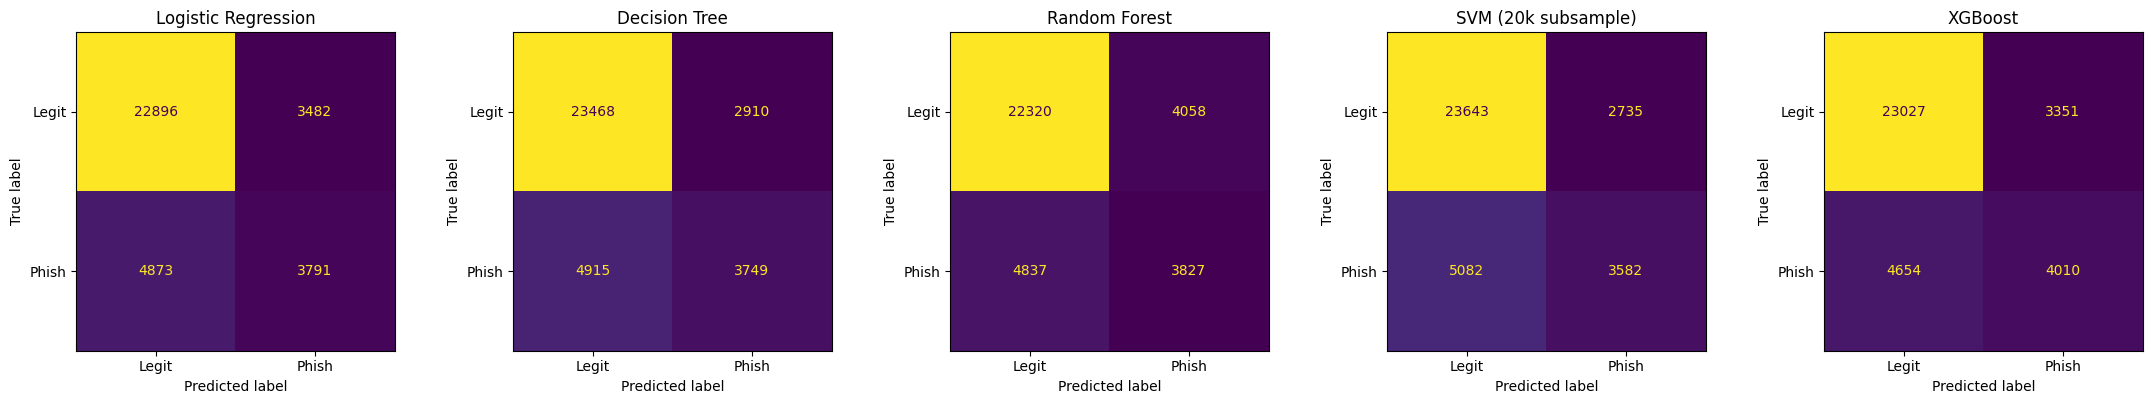

In [ ]:
import time
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

X = data.drop(columns=["site", "is_phish"]); y = data["is_phish"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
spw = (y_tr == 0).sum() / (y_tr == 1).sum()
print("Phishing share:", round(y.mean(), 3), "| majority-class accuracy:", round(1 - y.mean(), 3))

models = {
 "Logistic Regression": Pipeline([("s", StandardScaler()),
                         ("c", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
 "Decision Tree": DecisionTreeClassifier(max_depth=12, class_weight="balanced", random_state=42),
 "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                         n_jobs=-1, random_state=42),
 "SVM (20k subsample)": Pipeline([("s", StandardScaler()),
                         ("c", SVC(probability=True, class_weight="balanced", random_state=42))]),
 "XGBoost": XGBClassifier(eval_metric="logloss", scale_pos_weight=spw, random_state=42, n_jobs=-1),
}

rows = []
for name, m in models.items():
    t0 = time.time()
    if name.startswith("SVM"):
        idx = X_tr.sample(20000, random_state=42).index
        m.fit(X_tr.loc[idx], y_tr.loc[idx])
    else:
        m.fit(X_tr, y_tr)
    tt = time.time() - t0
    pred, prob = m.predict(X_te), m.predict_proba(X_te)[:, 1]
    rows.append({"Model": name, "Precision": precision_score(y_te, pred),
                 "Recall": recall_score(y_te, pred), "F1": f1_score(y_te, pred),
                 "ROC-AUC": roc_auc_score(y_te, prob), "PR-AUC": average_precision_score(y_te, prob),
                 "Train time (s)": tt})
results = pd.DataFrame(rows).round(4).set_index("Model")
results.to_csv(f"{base}/reports/domain_results.csv")
print(results)

fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (n, m) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_te, y_te, ax=ax, display_labels=["Legit", "Phish"], colorbar=False)
    ax.set_title(n)
plt.tight_layout(); plt.savefig(f"{base}/reports/confusion_matrices.png", dpi=150); plt.show()

In [ ]:
import joblib, sklearn, xgboost
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

search = RandomizedSearchCV(
    XGBClassifier(eval_metric="logloss", scale_pos_weight=spw, random_state=42, n_jobs=-1),
    {"n_estimators": [200, 400], "max_depth": [4, 6, 8], "learning_rate": [0.05, 0.1, 0.2],
     "subsample": [0.8, 1.0], "colsample_bytree": [0.8, 1.0]},
    n_iter=12, scoring="f1", cv=StratifiedKFold(3, shuffle=True, random_state=42),
    random_state=42, n_jobs=-1).fit(X_tr, y_tr)
best = search.best_estimator_
print("Best params:", search.best_params_, "| CV F1:", round(search.best_score_, 4))


Best params: {'subsample': 0.8, 'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.8} | CV F1: 0.507


In [ ]:

pred, prob = best.predict(X_te), best.predict_proba(X_te)[:, 1]
print("Tuned XGB | Prec:", round(precision_score(y_te, pred), 4), "Recall:", round(recall_score(y_te, pred), 4),
      "F1:", round(f1_score(y_te, pred), 4), "PR-AUC:", round(average_precision_score(y_te, prob), 4))

tf = pd.DataFrame([F.extract_features(s) for s in tranco["domain"]])[X.columns]
print("Tranco top-1000 flagged as phishing:", int(best.predict(tf).sum()), "/ 1000")

joblib.dump({"model": best, "columns": list(X.columns),
             "sklearn": sklearn.__version__, "xgboost": xgboost.__version__},
            f"{base}/models/phishing_model.pkl")



Tuned XGB | Prec: 0.5657 Recall: 0.4499 F1: 0.5012 PR-AUC: 0.5963
Tranco top-1000 flagged as phishing: 242 / 1000


['/content/drive/MyDrive/Phishing_Detection_Project/models/phishing_model.pkl']

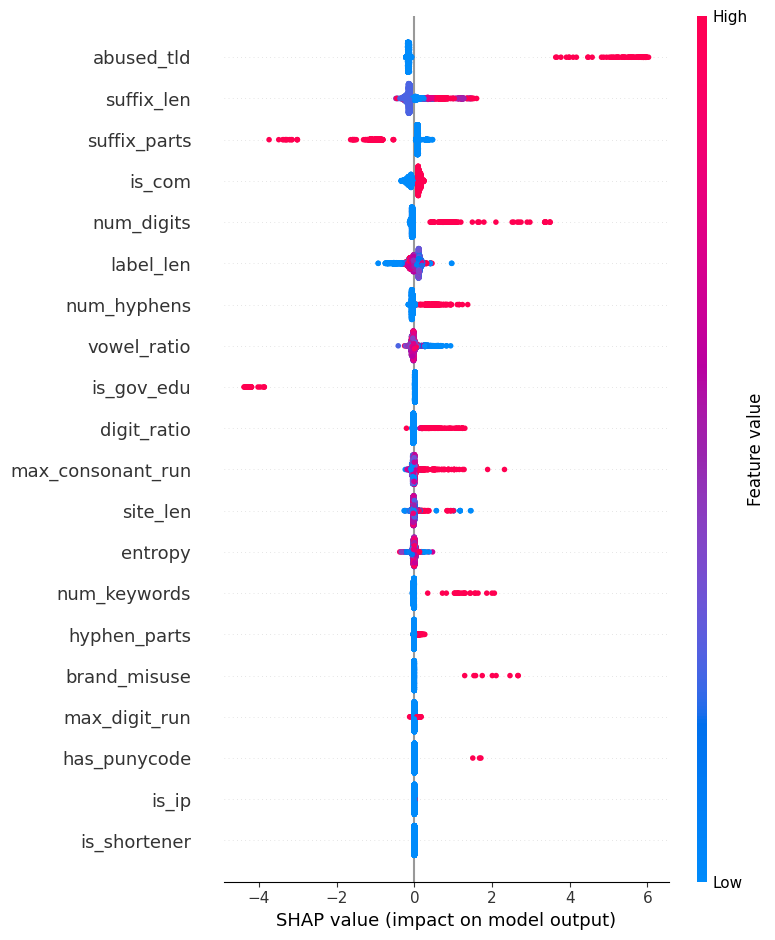

1.6.1 3.4.1


In [ ]:
import shap
sv = shap.TreeExplainer(best).shap_values(X_te.sample(3000, random_state=1))
shap.summary_plot(sv, X_te.sample(3000, random_state=1), show=False)
plt.savefig(f"{base}/reports/shap_summary.png", dpi=150, bbox_inches="tight"); plt.show()
print(sklearn.__version__, xgboost.__version__)

In [ ]:
from sklearn.metrics import accuracy_score

tr = tranco[["domain"]].copy()
tr["p"] = best.predict_proba(tf)[:, 1]
tr["flag"] = tr["p"] >= 0.5
print(tr[tr.flag].sort_values("p", ascending=False).head(25))
print(tf.assign(flag=tr.flag.values).groupby("flag").mean().T.round(2))

print("Test accuracy:", round(accuracy_score(y_te, best.predict(X_te)), 4),
      "| baseline:", round(1 - y_te.mean(), 4))

prob = best.predict_proba(X_te)[:, 1]
for t in [0.5, 0.6, 0.7, 0.8, 0.9]:
    pr = prob >= t
    print(f"t={t}: precision={precision_score(y_te, pr):.3f} "
          f"recall={recall_score(y_te, pr):.3f} flagged={pr.mean():.1%} "
          f"tranco_flagged={(tr.p >= t).sum()}")

                    domain         p  flag
106                   t.me  0.964845  True
227                   t.co  0.964845  True
674                   g.co  0.964845  True
132    amazon-adsystem.com  0.948099  True
866  ssl-images-amazon.com  0.940832  True
401        volcfcdndvs.com  0.936194  True
640  googletagservices.com  0.930136  True
173   googleadservices.com  0.929655  True
34   googleusercontent.com  0.927678  True
38     microsoftonline.com  0.927572  True
963        xhamster46.desi  0.919183  True
51       googledomains.com  0.918116  True
512          ipv4only.arpa  0.916943  True
52                   x.com  0.913191  True
5           googleapis.com  0.913127  True
207             ttdns2.com  0.912733  True
757     vercel-dns-017.com  0.912712  True
557     vercel-dns-016.com  0.912712  True
774            cdnhwc1.com  0.912644  True
22    googletagmanager.com  0.910984  True
685       vercel-dns-3.com  0.904817  True
187          cdn-apple.com  0.903851  True
332        

In [ ]:
import os, joblib
from google.colab import drive
drive.mount('/content/drive')

base = "/content/drive/MyDrive/Phishing_Detection_Project"
if "best" not in globals():
    best = joblib.load(f"{base}/models/phishing_model.pkl")["model"]

best.save_model(f"{base}/models/xgb_model.json")
print("Saved:", os.path.getsize(f"{base}/models/xgb_model.json"), "bytes")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved: 902185 bytes
